# Forecasting German electricity prices: the whole process, step by step

This notebook walks through **everything** the project does, in the order you would do it yourself, and explains **why** at each step.
It is written for someone who knows a little Python and wants to understand how a forecasting project is built properly, not just
which model was used.

**How to read it.** Every section has three parts: a short explanation, the code, and a "What you should see" note that tells you how
to read the output. You can run the cells from top to bottom. With the saved data it takes about half a minute; the first time, `make data` downloads about 4.5 years of data (a few minutes).

**It uses the real project code** (`from epf import ...`), not a copy. So what you learn here is exactly what runs in the daily job.

| # | Section | The question it answers |
|---|---|---|
| 1 | The task | What exactly are we predicting, and what are we allowed to know? |
| 2 | The data | What does German electricity price data look like? |
| 3 | Features without leakage | How do we turn the past into model inputs without cheating? |
| 4 | Baselines and error measures | What must a model beat, and how do we measure it? |
| 5 | The model | How does a quantile model give us a forecast and an interval? |
| 6 | Calibrating the interval | Why was the interval too confident, and how do we fix it? |
| 7 | The backtest | How do we test honestly over a whole year? |
| 8 | What drives the forecast | Why does the model predict what it predicts? |
| 9 | Anomalies | Which hours are surprising, and why? |
| 10 | From notebook to product | How does this run every day, and how do we know it still works? |

In [1]:
# --- Setup -------------------------------------------------------------------------------------------------------
import json
import warnings
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from epf import anomaly, config, features, metrics, monitor
from epf.backtest import CALIBRATION_DAYS
from epf.data import build, quality
from epf.models.gbm import QuantileForecaster

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 140, "display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY, ORANGE, GREEN = "#1f6feb", "#8b949e", "#d9822b", "#1a7f37"

# The data file is made by `make data` (a few minutes the first time, then cached). If it is missing, make it now.
DATASET = config.PROCESSED_DIR / "dataset.parquet"
if not DATASET.exists():
    print("Downloading the data (first run only) ...")
    build.save_dataset()
print("Project:", config.ROOT.name)

Project: energy-price-forecast


## 1. The task: what exactly are we predicting?

Germany sells electricity the day before it is delivered. Every day at **12:00 (Berlin time)** an auction fixes the **24 hourly prices
for the next day**. These are the *day-ahead prices*.

Our task, in one sentence:

> **Predict the 24 hourly day-ahead prices of day D, using only what is known at 12:00 on day D-1.**

This sentence is the most important line of the project. It decides which information we may use, and a forecasting project that
does not write it down usually cheats without noticing (this is called **data leakage**).

What is known at 12:00 on day D-1?

| Known (allowed) | Not known (forbidden) |
|---|---|
| All prices up to and including day D-1 | The prices of day D (that is what we predict) |
| Weather **forecasts** for day D | Weather that was **measured** on day D |
| Calendar facts: hour, weekday, holiday | Anything published after the auction |

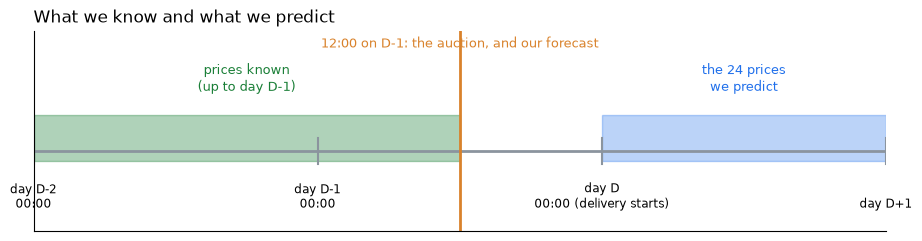

In [2]:
# A small timeline to make the rule visible.
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.set_xlim(0, 72)
ax.set_ylim(0, 3)
ax.set_yticks([])
ax.set_xticks([])
ax.grid(False)
ax.axhline(1.2, color=GREY, lw=2)
for hour, label in [(0, "day D-2\n00:00"), (24, "day D-1\n00:00"), (48, "day D\n00:00 (delivery starts)"), (72, "day D+1")]:
    ax.plot([hour, hour], [1.0, 1.4], color=GREY)
    ax.text(hour, 0.35, label, ha="center", fontsize=8.5)
ax.axvspan(0, 36, ymin=0.35, ymax=0.58, color=GREEN, alpha=0.35)
ax.text(18, 2.1, "prices known\n(up to day D-1)", ha="center", color=GREEN, fontsize=9.5)
ax.axvline(36, color=ORANGE, lw=2)
ax.text(36, 2.75, "12:00 on D-1: the auction, and our forecast", ha="center", color=ORANGE, fontsize=9.5)
ax.axvspan(48, 72, ymin=0.35, ymax=0.58, color=BLUE, alpha=0.3)
ax.text(60, 2.1, "the 24 prices\nwe predict", ha="center", color=BLUE, fontsize=9.5)
ax.set_title("What we know and what we predict", loc="left")
plt.show()

**What you should see.** Everything left of the orange line is allowed as an input. Everything in the blue block is the target.
Later we will prove with a test, not just a promise, that no input comes from the blue block.

## 2. The data

Two public sources, both free:

- **SMARD** (Bundesnetzagentur): the hourly day-ahead price (DE-LU), plus the grid operators' forecasts of load, wind and solar.
- **Open-Meteo**: weather *forecasts* (temperature, solar radiation, wind speed at 100 m) at four places that stand for the country.

`make data` downloads them, caches the raw files, and builds one table with **one row per hour**. The index is in UTC, which has no
daylight-saving jumps, so rows never disappear or repeat. We convert to Berlin time only when we need the local clock.

In [3]:
frame = build.load_dataset()
print(frame.shape, "rows x columns")
print("from", frame.index.min(), "to", frame.index.max())
frame.tail(5)

(42215, 9) rows x columns
from 2022-01-01 00:00:00+00:00 to 2026-10-25 22:00:00+00:00


,price,load_fc,wind_onshore_fc,wind_offshore_fc,solar_fc,temp,rad,wind_ns,wind_inland
time,,,,,,,,,
2026-10-25 18:00:00+00:00,57.01,53695.99,NaN,NaN,NaN,10.60,0.00,67.70,40.57
2026-10-25 19:00:00+00:00,43.19,51844.26,NaN,NaN,NaN,10.17,0.00,65.80,38.90
2026-10-25 20:00:00+00:00,24.52,49868.06,NaN,NaN,NaN,9.70,0.00,67.30,36.50
2026-10-25 21:00:00+00:00,29.62,47811.48,NaN,NaN,NaN,9.53,0.00,59.70,38.33
2026-10-25 22:00:00+00:00,14.90,45161.06,NaN,NaN,NaN,9.47,0.00,54.90,37.73


**What you should see.** One row per hour. `price` is in EUR/MWh. The `*_fc` columns are the grid operators' **forecasts** (not measured
values). `temp`, `rad`, `wind_ns`, `wind_inland` are weather forecasts.

Look at the **last rows, which are tomorrow**. Depending on the time of day you run this, the price may already be there (the auction ran at 12:00) but the grid
operators' **wind and solar forecasts are still missing (`NaN`)**: they are published in the evening. Remember this, it is the reason one of our two feature sets cannot be
used in the morning (section 3).

Before using any data, check its quality. Cheap checks catch expensive mistakes.

In [4]:
report = quality.quality_report(frame)
print(json.dumps({k: v for k, v in report.items() if k != "missing_share"}, indent=1))
print("share of missing values per column:", report["missing_share"])

{
 "rows": 42215,
 "first": "2022-01-01T00:00:00+00:00",
 "last": "2026-10-25T22:00:00+00:00",
 "missing_hours": 0,
 "duplicate_hours": 0,
 "dst_short_days": 6,
 "dst_long_days": 5,
 "negative_price_hours": 1862,
 "price_min": -500.0,
 "price_max": 936.28,
 "price_mean": 122.41
}
share of missing values per column: {'price': 0.0, 'load_fc': 0.0, 'wind_onshore_fc': 0.0012, 'wind_offshore_fc': 0.0006, 'solar_fc': 0.0012, 'temp': 0.0, 'rad': 0.0, 'wind_ns': 0.0, 'wind_inland': 0.0}


**What you should see.** No missing hours and no duplicates, so the table is a clean hourly series. A few days have 25 hours and a few have 23 hours (the
clock changes), which we must handle with care in section 3. Note the number of **negative price hours** (over a thousand): in Germany, when there is more wind and
sun than demand, prices can fall below zero. This is why we will avoid error measures that divide by the price (more on that in section 4).

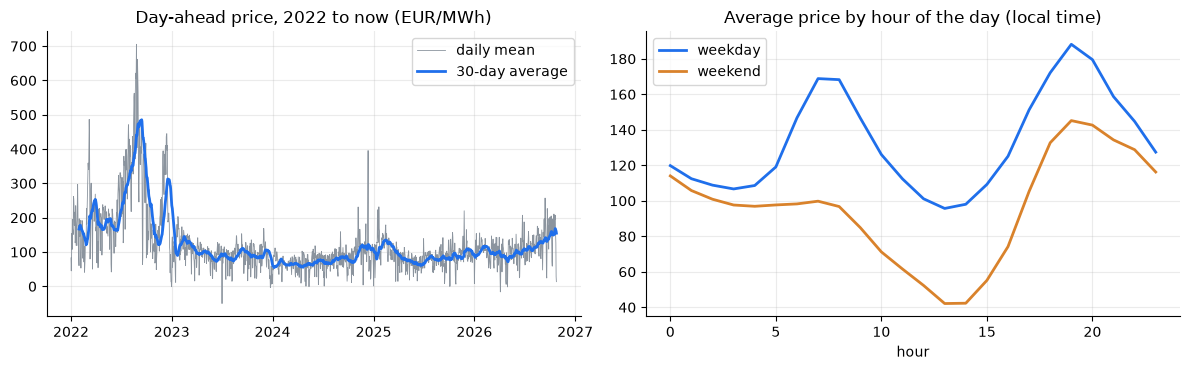

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
daily = frame["price"].resample("D").mean()
axes[0].plot(daily.index, daily, color=GREY, lw=0.6, label="daily mean")
axes[0].plot(daily.index, daily.rolling(30).mean(), color=BLUE, lw=2, label="30-day average")
axes[0].set_title("Day-ahead price, 2022 to now (EUR/MWh)")
axes[0].legend()

local = frame["price"].dropna().copy()
local.index = local.index.tz_convert(config.TIMEZONE)
profile = local.groupby([local.index.hour, local.index.dayofweek >= 5]).mean().unstack()
profile.columns = ["weekday", "weekend"]
profile.plot(ax=axes[1], color=[BLUE, ORANGE], lw=2)
axes[1].set_title("Average price by hour of the day (local time)")
axes[1].set_xlabel("hour")
plt.tight_layout()
plt.show()

**What you should see.**

- **Left:** the energy crisis of 2022 (very high prices), then a calmer level, with big swings inside every year. A model has to cope with a
  market whose level changes. That is one reason we always train on the past only and watch the model after release.
- **Right:** a clear **daily shape**: cheap at night, a morning peak, a **dip at midday when solar power floods the market**, and an
  evening peak. The weekend line sits lower. Most of the predictable signal is this shape, plus the weather.

## 3. Features without leakage

A **feature** is one input column the model sees for each hour we predict. We build three groups, all allowed by the rule in section 1:

| Group | Examples | Why it helps |
|---|---|---|
| Calendar | hour, weekday, month, public holiday | Demand and prices follow a daily and weekly rhythm |
| Weather forecast for day D | temperature, solar radiation, wind | Wind and sun lower prices, cold raises demand |
| Price history | the same hour 1, 2, 3 and 7 days earlier; mean, min, max of the day before; mean of the last 7 days | Prices are persistent: today's level says a lot about tomorrow's |

We call this the **safe** feature set, because every column is known before the auction. A second set, **full**, also contains the grid operators'
load, wind and solar forecasts. It is more accurate, but those forecasts for tomorrow come out too late (wind and solar in the evening), so
we use *full* only as a reference.

In [6]:
featured = features.add_features(frame)
target_day = date(2026, 9, 14)
start, end = [t for t in (pd.Timestamp(target_day, tz=config.TIMEZONE).tz_convert("UTC"), pd.Timestamp(date(2026, 9, 15), tz=config.TIMEZONE).tz_convert("UTC"))]
one_day = featured[(featured.index >= start) & (featured.index < end)]
one_day[["hour", "weekday", "temp", "rad", "wind_ns", "price_lag_24", "price_lag_168", "price_mean_prev_day", "price"]].head(8)

,hour,weekday,temp,rad,wind_ns,price_lag_24,price_lag_168,price_mean_prev_day,price
time,,,,,,,,,
2026-09-13 22:00:00+00:00,0,0,17.13,0.00,22.50,177.83,155.50,166.10,201.71
2026-09-13 23:00:00+00:00,1,0,16.97,0.00,19.90,167.60,150.86,166.10,187.89
2026-09-14 00:00:00+00:00,2,0,16.80,0.00,21.40,163.03,148.32,166.10,184.17
2026-09-14 01:00:00+00:00,3,0,16.77,0.00,13.80,161.73,148.21,166.10,183.87
2026-09-14 02:00:00+00:00,4,0,16.67,0.00,10.90,164.06,151.84,166.10,183.76
2026-09-14 03:00:00+00:00,5,0,16.30,0.00,17.70,168.03,172.87,166.10,202.13
2026-09-14 04:00:00+00:00,6,0,16.37,0.00,12.80,175.27,207.48,166.10,254.69
2026-09-14 05:00:00+00:00,7,0,16.10,0.67,9.40,178.93,220.36,166.10,316.91


**What you should see.** For 14 Sep 2026, eight of its 24 hours. `price_lag_24` is the price of the same hour *yesterday* (also the seasonal naive forecast with m = 24, see section 4), `price_lag_168` the
same hour *last week* (seasonal naive, m = 168). The last column, `price`, is the **target**: the model never sees it as an input.

### The leakage test: prove it, don't promise it
If our features are clean, then changing the prices of the target day must not change **any** feature of that day. Let us test exactly that.

In [7]:
tampered = frame.copy()
mask = (tampered.index >= start) & (tampered.index < end)
tampered.loc[mask, "price"] += 1000          # a crazy change to the prices of the target day

after = features.add_features(tampered)
day_before = featured.loc[mask, features.FULL_FEATURES]
day_after = after.loc[mask, features.FULL_FEATURES]
print("Features of day D unchanged when its prices change:", day_before.equals(day_after))

Features of day D unchanged when its prices change: True


**What you should see.** `True`. This is the same check that runs as a unit test (`tests/test_features.py`) on every push. If someone later adds
a feature that peeks at the target day, this test fails and the pipeline stops.

### A subtle trap: the 25-hour day
Twice a year the clocks change. On **25 Oct 2026** the local day has **25 hours**. A lazy "same hour yesterday" is `price.shift(24)`, but 24 hours
before the last hour of that day is a time *inside the same day*, which we do not know yet. A real bug of exactly this kind was found in this project.
The fix is to take the lag on the **local clock**: the same local hour on the previous local day.

In [8]:
# day_bounds gives the start and end of a LOCAL day, in UTC (it handles 23, 24 and 25 hour days)
from epf.forecast import day_bounds

day_start, day_end = day_bounds(date(2026, 10, 25))
long_day = frame[(frame.index >= day_start) & (frame.index < day_end)].copy()
long_day["local time"] = long_day.index.tz_convert(config.TIMEZONE).strftime("%H:%M")
long_day["naive: shift(24)"] = frame["price"].shift(24).reindex(long_day.index)
long_day["our lag (local clock)"] = featured.loc[long_day.index, "price_lag_24"]
print("Hours in this local day:", len(long_day))
long_day[["local time", "naive: shift(24)", "our lag (local clock)"]].tail(4)

Hours in this local day: 25


,local time,naive: shift(24),our lag (local clock)
time,,,
2026-10-25 19:00:00+00:00,20:00,30.28,58.18
2026-10-25 20:00:00+00:00,21:00,27.67,30.28
2026-10-25 21:00:00+00:00,22:00,13.49,27.67
2026-10-25 22:00:00+00:00,23:00,7.55,13.49


**What you should see.** The day has 25 rows. After the clock change the two columns differ. For the row "22:00" the naive shift gives the price of **yesterday 23:00**
(one local hour off), while our lag gives yesterday 22:00. For the very last row, "23:00", the naive value is the price from **00:00 of the same day**: a price we
do not know at forecast time. That is a leak. Our lag takes the 23:00 of the previous day instead.

## 4. Baselines and error measures

Before building a clever model, decide **what it has to beat**. Forecasting has a standard ladder of simple, well-understood methods, named as in the textbook
*Forecasting: Principles and Practice* (Hyndman and Athanasopoulos). A model is only impressive if it beats the **best** of them, not just the weakest.

| Method | In words |
|---|---|
| **Seasonal naive, m = 24** (`price_lag_24`) | The forecast is the value **one season ago**. *m* is the season length. With m = 24 the season is one day: "the same hour yesterday". |
| **Seasonal naive, m = 168** (`price_lag_168`) | The same idea with a season of one week (168 hours): "the same hour last week". |
| **Seasonal average** | The mean of the same hour over the last 4 weeks. It smooths out one unusual week. |
| **Holt-Winters exponential smoothing, ETS(A,N,A), m = 24** | Keeps a running **level** and a daily **seasonal pattern** and updates both after each new hour, giving recent hours more weight. The letters stand for additive error, no trend, additive seasonality. |
| **SARIMA(1,0,0)(1,1,0)24** | An autoregressive model: each hour depends on the previous hour (AR(1)), after the daily pattern is removed by a 24-hour seasonal difference, and a seasonal AR(1) is fitted on that difference. |
| **SARIMA(1,0,1)(0,1,1)24** | ARMA(1,1) plus a seasonal MA(1) on the 24-hour seasonal difference: it also learns from its own recent forecast errors (an "airline-type" model). |
| **SARIMAX(1,0,1)(0,1,1)24 + weather forecasts** | The same model, with the four weather forecasts (temperature, solar radiation, North Sea wind, inland wind) added as **exogenous regressors**: outside information that is known before the auction. |

The last four are statistical models that have to be **fitted**. Each one is refitted **for every day** on the last 28 days of prices, using only prices **before that day**,
so they know exactly what our machine learning model knows and the comparison is fair. We do not refit them in this notebook (it takes minutes). The full-backtest
numbers come from `docs/results.json`, which `make backtest` writes.

**A note on ARX and SARIMAX.** The first five methods use only past prices. The **SARIMAX** adds the weather forecasts as exogenous regressors: it improves on its SARIMA twin, but
it stays slightly behind Holt-Winters. The closest thing to an *ARX* model (autoregression plus exogenous inputs) in this project is the **ridge regression** of section 7: a linear model
on price lags (the autoregressive part) plus weather and calendar inputs.

We split the data in time: train on everything up to 30 June 2026 and test on
July to September 2026. We never split randomly, because random splits mix the future into the training data.

In [9]:
table = features.training_table(frame)          # only rows that have a price and all features
split = pd.Timestamp("2026-07-01", tz=config.TIMEZONE).tz_convert("UTC")
end_test = pd.Timestamp("2026-10-01", tz=config.TIMEZONE).tz_convert("UTC")
train, test = table[table.index < split], table[(table.index >= split) & (table.index < end_test)]
print(f"train: {len(train):,} hours   test: {len(test):,} hours")

metrics.score_table(test["price"], {
    "seasonal naive, m=24 (same hour yesterday)": test["price_lag_24"],
    "seasonal naive, m=168 (same hour last week)": test["price_lag_168"],
})

train: 39,238 hours   test: 2,208 hours


,MAE,RMSE,sMAPE %
"seasonal naive, m=24 (same hour yesterday)",33.51,52.47,51.45
"seasonal naive, m=168 (same hour last week)",42.94,64.50,58.96


That was a short window with two baselines. Here are **all** the baselines, and our models, over the **full 12-month backtest**
(computed once by `make backtest`, stored in `docs/results.json`). The statistical models are the slow part, which is why we read them instead of refitting.

In [10]:
results = json.loads((config.DOCS_DIR / "results.json").read_text())
print("backtest period:", results["from"][:10], "to", results["to"][:10], "  hours:", f"{results['rows']:,}")
pd.DataFrame(results["models"]).T.round(2)

backtest period: 2025-09-30 to 2026-09-30   hours: 8,760


,MAE,RMSE,sMAPE %
"seasonal naive, m=24 (same hour yesterday)",29.82,47.34,45.24
"seasonal naive, m=168 (same hour last week)",37.38,57.46,52.70
"seasonal average, 4 weeks",32.22,46.60,44.80
"Holt-Winters ETS(A,N,A), m=24",25.19,39.06,39.13
"SARIMA(1,0,0)(1,1,0)24 (AR)",27.37,43.78,41.79
"SARIMA(1,0,1)(0,1,1)24 (ARMA + seasonal MA)",26.66,41.61,40.31
"SARIMAX(1,0,1)(0,1,1)24 + weather forecasts",25.62,40.06,39.33
"ridge regression (AR lags, weather, calendar)",23.81,34.52,37.42
"LightGBM, safe inputs (released model)",19.58,31.25,32.30
"LightGBM, with grid forecasts (reference)",17.60,28.79,31.66


**What you should see.** Three error measures for each model in the two tables above. In the 12-month table, Holt-Winters is the best of the classical baselines, and the seasonal naive forecast with m = 168
is the weakest. Keep that in mind in section 7.

The three measures:

- **MAE** (mean absolute error): the average miss in EUR/MWh. Easy to understand. This is our main number.
- **RMSE**: like MAE, but big misses count more. It reacts to price spikes.
- **sMAPE**: a percentage error that is safe when prices are near zero.

### Why we do not use MAPE
MAPE divides each error by the actual price. Let us see what happens when prices are near zero.

In [11]:
near_zero = test[test["price"].abs() < 1].head(5)
mape_rows = pd.DataFrame({
    "actual": near_zero["price"], "forecast": near_zero["price_lag_24"],
    "abs error": (near_zero["price"] - near_zero["price_lag_24"]).abs(),
})
mape_rows["MAPE of this hour, %"] = mape_rows["abs error"] / mape_rows["actual"].abs() * 100
mape_rows

,actual,forecast,abs error,"MAPE of this hour, %"
time,,,,
2026-07-02 09:00:00+00:00,-0.07,119.45,119.52,170742.86
2026-07-02 14:00:00+00:00,-0.51,99.39,99.90,19588.24
2026-07-03 08:00:00+00:00,-0.10,5.53,5.63,5630.00
2026-07-03 15:00:00+00:00,-0.05,2.90,2.95,5900.00
2026-07-04 07:00:00+00:00,0.99,9.57,8.58,866.67


**What you should see.** An error of a few EUR/MWh becomes a MAPE of several hundred or thousand percent, because the actual price is almost zero.
Averaged over a year, a handful of such hours would dominate the number. With about 1,900 negative-price hours in the data, MAPE would be
meaningless, so we use MAE, RMSE and sMAPE.

## 5. The model: a forecast and an interval

We use **LightGBM**, a gradient boosting model: many small decision trees, each correcting the mistakes of the ones before.

A single number ("the price at 18:00 will be 54") hides how sure we are. So we train **three** models with a *quantile* objective:

- the **10 %** model: the price should be above this in 90 % of cases
- the **50 %** model (the *median*): our main forecast
- the **90 %** model: the price should be below this in 90 % of cases

The band between the 10 % and the 90 % forecast is an **80 % prediction interval**: it should contain the real price in about 80 % of the hours.

### How a quantile model learns: the pinball loss
For the median, the loss is the usual absolute error. For other quantiles the loss is *tilted*: for the 90 % model, predicting too low costs 9 times
more than predicting too high. So the model learns to sit high enough that only 10 % of prices land above it.

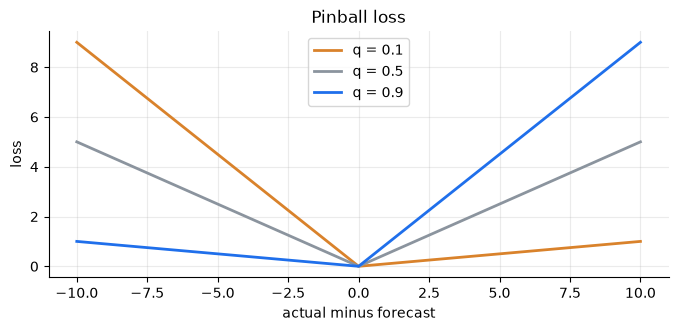

In [12]:
errors = np.linspace(-10, 10, 201)   # error = actual - forecast
fig, ax = plt.subplots(figsize=(8, 3.2))
for q, color in [(0.1, ORANGE), (0.5, GREY), (0.9, BLUE)]:
    ax.plot(errors, np.maximum(q * errors, (q - 1) * errors), color=color, lw=2, label=f"q = {q}")
ax.set_xlabel("actual minus forecast")
ax.set_ylabel("loss")
ax.set_title("Pinball loss")
ax.legend()
plt.show()

**What you should see.** For q = 0.9 (blue) the line is steep on the right: if the actual price is above the forecast (positive error), the penalty is large,
so the model pushes its forecast up. For q = 0.1 (orange) it is the other way round. For q = 0.5 (grey) the loss is symmetric.

Now we train the three models on the training data and forecast the test period. At first **without** any correction.

In [13]:
raw_model = QuantileForecaster(calibration_days=0).fit(train)       # calibration_days=0: no correction yet
forecast = raw_model.predict(test)
print("safe features used by the model:", len(raw_model.features))
print("MAE of the median forecast:", round(metrics.mae(test["price"], forecast["q50"]), 2), "EUR/MWh   (seasonal naive m=168: ", round(metrics.mae(test["price"], test["price_lag_168"]), 2), ")")
print("share of real prices inside the raw 80 % interval:", round(metrics.coverage(test["price"], forecast["q10"], forecast["q90"]), 3))

safe features used by the model: 16
MAE of the median forecast: 24.56 EUR/MWh   (seasonal naive m=168:  42.94 )
share of real prices inside the raw 80 % interval: 0.715


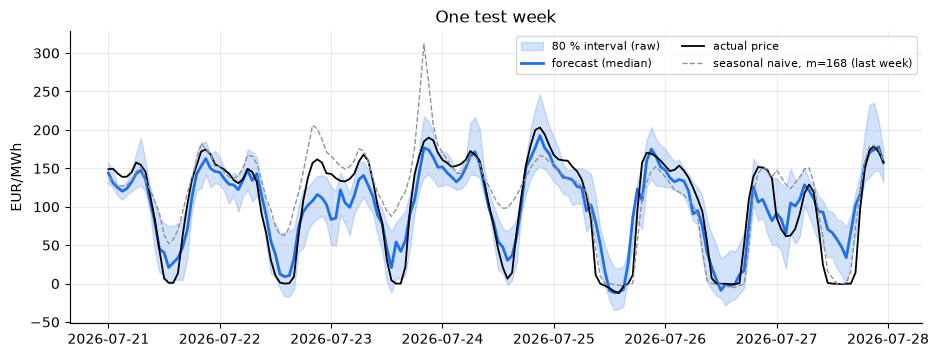

In [14]:
week = test.iloc[24 * 20: 24 * 27]
fw = forecast.loc[week.index]
local_index = week.index.tz_convert(config.TIMEZONE)
fig, ax = plt.subplots()
ax.fill_between(local_index, fw["q10"], fw["q90"], color=BLUE, alpha=0.2, label="80 % interval (raw)")
ax.plot(local_index, fw["q50"], color=BLUE, lw=2, label="forecast (median)")
ax.plot(local_index, week["price"], color="black", lw=1.3, label="actual price")
ax.plot(local_index, week["price_lag_168"], color=GREY, lw=1, ls="--", label="seasonal naive, m=168 (last week)")
ax.set_ylabel("EUR/MWh")
ax.legend(ncol=2, fontsize=8)
ax.set_title("One test week")
plt.show()

**What you should see.** The blue line follows the daily rhythm of the black line far better than the dashed grey "seasonal naive, m=168" line. The model **beats that baseline**
(sections 4 and 7 compare it with the stronger classical ones). But look at the printed coverage: the "80 %" interval contains clearly **fewer than 80 %** of the real prices. The model is too confident.
That is typical for quantile models, and it is the next problem to solve.

## 6. Calibrating the interval (conformal prediction)

**The idea in plain words.** Hold back the most recent 60 days of the training data. Train on the earlier data, then check on those 60 days **how
far outside the interval the real prices fell**. If the interval is too narrow, the real prices fall outside it often, and by some amount. We take that amount
(the right quantile of these misses) and **widen every interval by it**. This is called *conformalized quantile regression*. We do it step by step
below so there is no magic.

calibration hours: 1,440   offset: 2.5 EUR/MWh (interval grows by this at each end)


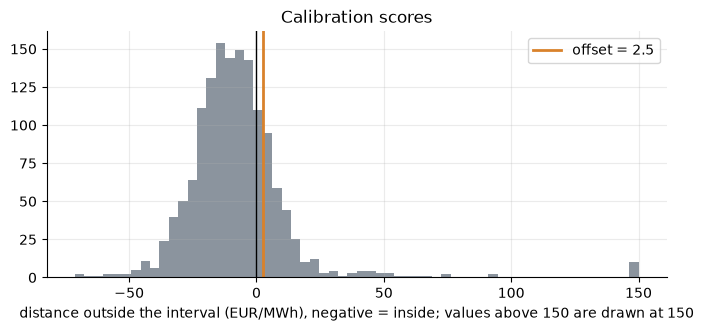

In [15]:
# 1. split the training data in time: the last 60 days are the calibration set
cut = train.index.max() - pd.Timedelta(days=CALIBRATION_DAYS)
fit_part, calib = train[train.index <= cut], train[train.index > cut]

# 2. train on the earlier part, predict the calibration days
helper = QuantileForecaster(calibration_days=0).fit(fit_part)
calib_forecast = helper.predict(calib)

# 3. how far outside the interval is each real price? (negative = inside)
score = np.maximum(calib_forecast["q10"] - calib["price"], calib["price"] - calib_forecast["q90"])

# 4. the offset: the quantile of these scores that gives 80 % coverage
target = 0.8
level = min(1.0, target * (1 + 1 / len(score)))          # small-sample correction of conformal prediction
offset = float(np.quantile(score, level))
print(f"calibration hours: {len(score):,}   offset: {offset:.1f} EUR/MWh (interval grows by this at each end)")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(score.clip(-80, 150), bins=60, color=GREY)
ax.axvline(offset, color=ORANGE, lw=2, label=f"offset = {offset:.1f}")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("distance outside the interval (EUR/MWh), negative = inside; values above 150 are drawn at 150")
ax.set_title("Calibration scores")
ax.legend()
plt.show()

**What you should see.** Most scores are negative (the real price was inside the interval), with a tail to the right (it was outside by that much). The orange line marks the value
below which 80 % of the scores lie. Now apply it to the test period and compare coverage before and after.

In [16]:
widened_low, widened_high = forecast["q10"] - offset, forecast["q90"] + offset     # the helper's offset applied to the model from section 5
print("coverage before:", round(metrics.coverage(test["price"], forecast["q10"], forecast["q90"]), 3))
print("coverage after: ", round(metrics.coverage(test["price"], widened_low, widened_high), 3), "  (target 0.80)")

# The project class does the same in one line, and keeps the raw interval in extra columns:
final_model = QuantileForecaster(calibration_days=CALIBRATION_DAYS).fit(train)
print("offset learned by QuantileForecaster:", round(final_model.offset, 1))

coverage before: 0.715
coverage after:  0.751   (target 0.80)


offset learned by QuantileForecaster: 2.5


**What you should see.** Coverage moves towards 80 %, but in this short test window probably **not all the way**. The reason is worth understanding: the offset was measured
on the 60 days *before* the test window. If those days were calmer than the test months, the offset is a bit too small. Calibration fixes the *average* behaviour, not every
single period. Over the full 12-month backtest (section 7) the effect averages out much closer to 80 %. This is also why the monitoring in section 10 keeps checking the interval.

## 7. The backtest: an honest test over a whole year

One test window (three months) can be lucky. A **backtest** repeats the test many times, always as it would happen in reality:

```
month 1 :  train on everything before month 1  ->  forecast month 1
month 2 :  train on everything before month 2  ->  forecast month 2     (month 1 is now part of the training data)
...
month 12:  train on everything before month 12 ->  forecast month 12
```

This is called **rolling origin** evaluation. The model is retrained each month and only ever sees the past, like the real system will. The project's
`make backtest` does this for the last 12 months and saves the result; here we load it (if you have not run it, the cell below computes a shorter
3-month version, which takes about a minute).

In [17]:
saved = config.PROCESSED_DIR / "backtest.parquet"
if saved.exists():
    bt = pd.read_parquet(saved)
    print("Loaded the saved 12-month backtest.")
else:
    from epf.backtest import run_backtest
    from epf.features import FULL_FEATURES
    from epf.models.linear import RidgeForecaster
    bt = run_backtest(frame, months=3, extra_models={"ridge": RidgeForecaster,
                      "lgbm_full": lambda: QuantileForecaster(quantiles=(0.5,), features=FULL_FEATURES)})
    print("Computed a 3-month backtest.")

# the guard rail: every forecast must come AFTER the end of the data its model was trained on
print("every forecast is after its training data:", bool((bt.index >= bt["train_end"]).all()))
print("test months:", bt["train_end"].nunique(), "  hours forecast:", f"{len(bt):,}")

Loaded the saved 12-month backtest.
every forecast is after its training data: True
test months: 12   hours forecast: 8,760


**What you should see.** `True` for the guard rail: no forecast is made with data from its own future. Now compare all models on the same hours.

,MAE,RMSE,sMAPE %
"seasonal naive, m=24 (same hour yesterday)",29.82,47.34,45.24
"seasonal naive, m=168 (same hour last week)",37.38,57.46,52.70
"seasonal average, 4 weeks",32.22,46.60,44.80
"Holt-Winters ETS(A,N,A), m=24",25.19,39.06,39.13
"SARIMA(1,0,0)(1,1,0)24 (AR)",27.37,43.78,41.79
"SARIMA(1,0,1)(0,1,1)24 (ARMA + seasonal MA)",26.66,41.61,40.31
"SARIMAX(1,0,1)(0,1,1)24 + weather forecasts",25.62,40.06,39.33
"ridge regression (AR lags, weather, calendar)",23.81,34.52,37.42
"LightGBM, safe inputs (released)",19.58,31.25,32.30
"LightGBM, with grid forecasts (reference)",17.60,28.79,31.66


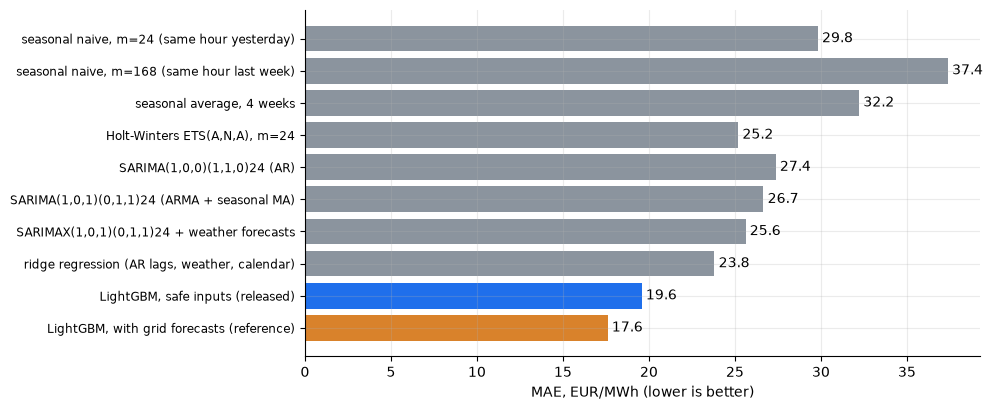

released model, MAE 19.58
  vs the best statistical baseline (Holt-Winters ETS(A,N,A), m=24, MAE 25.19): 22.3% lower error   <- the fair number
  vs seasonal naive, m=168 (MAE 37.38): 47.6% lower error   <- the weakest baseline


In [18]:
# label -> column of the backtest table. The classical columns exist in the saved 12-month backtest only.
STATISTICAL = {
    "seasonal naive, m=24 (same hour yesterday)": "naive_24",
    "seasonal naive, m=168 (same hour last week)": "naive_168",
    "seasonal average, 4 weeks": "sma_4w",
    "Holt-Winters ETS(A,N,A), m=24": "ets",
    "SARIMA(1,0,0)(1,1,0)24 (AR)": "sarima_ar",
    "SARIMA(1,0,1)(0,1,1)24 (ARMA + seasonal MA)": "sarima_arma",
    "SARIMAX(1,0,1)(0,1,1)24 + weather forecasts": "sarimax",
}
MODELS = {
    "ridge regression (AR lags, weather, calendar)": "ridge",
    "LightGBM, safe inputs (released)": "q50",
    "LightGBM, with grid forecasts (reference)": "lgbm_full",
}
models = {label: bt[col] for label, col in {**STATISTICAL, **MODELS}.items() if col in bt}
scores = metrics.score_table(bt["price"], models)
display(scores)

colors = [BLUE if n.startswith("LightGBM, safe") else ORANGE if n.startswith("LightGBM, with") else GREY for n in scores.index]
fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(scores.index, scores["MAE"], color=colors)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.invert_yaxis()
ax.set_xlabel("MAE, EUR/MWh (lower is better)")
ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout()
plt.show()

released = scores.loc["LightGBM, safe inputs (released)", "MAE"]
naive_168 = scores.loc["seasonal naive, m=168 (same hour last week)", "MAE"]
classical = [n for n in STATISTICAL if n in scores.index]
best = scores.loc[classical, "MAE"].idxmin()
print(f"released model, MAE {released:.2f}")
print(f"  vs the best statistical baseline ({best}, MAE {scores.loc[best, 'MAE']:.2f}): {1 - released / scores.loc[best, 'MAE']:.1%} lower error   <- the fair number")
print(f"  vs seasonal naive, m=168 (MAE {naive_168:.2f}): {1 - released / naive_168:.1%} lower error   <- the weakest baseline")
if len(classical) == 2:
    print("(This run has only the two seasonal naive baselines: run `make backtest` to get all statistical models.)")

**What you should see.**

- Each step up the ladder helps: the statistical models improve on the seasonal naive forecasts (Holt-Winters is the best of them; the SARIMAX with weather forecasts helps its SARIMA twin but does not beat it), the
  ridge regression with weather and calendar inputs beats all of them, and LightGBM improves on that. Ridge is the closest thing to an ARX model here. Complexity is only worth it when it is measured.
- The **orange bar** (with grid operators' forecasts) is the best, but we **cannot release it** because those forecasts come too late. We report it honestly as the ceiling.
- The printed lines below the chart give the gains for the data you loaded. For the full 12 months, the released model's MAE is **19.58**. That is **22.3 % lower than the best
  statistical baseline** (Holt-Winters ETS(A,N,A), MAE 25.19) and **47.6 % lower than seasonal naive, m = 168** (MAE 37.38). **The first number, 22.3 %, is the fair one to quote**,
  because it compares with the strongest simple method. The 47.6 % compares with the weakest baseline and looks bigger than it is.

Averages hide a lot. Where is the model weak?

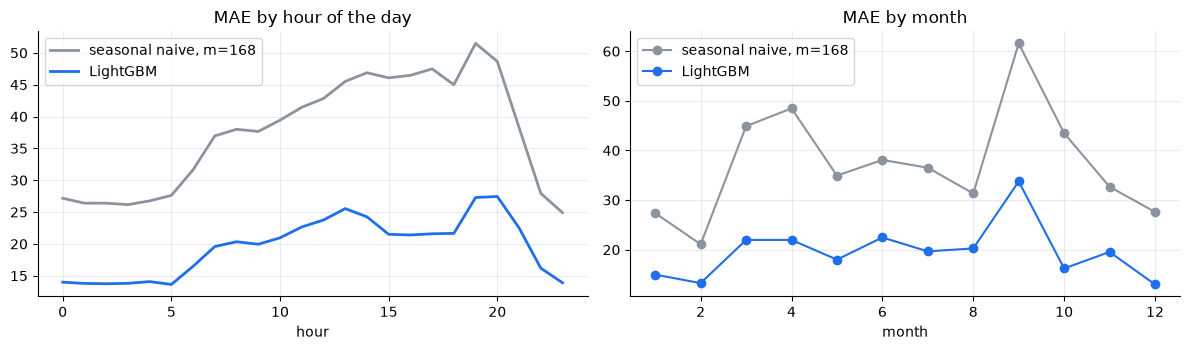

80 % interval coverage over the whole backtest: raw 69.5%  ->  calibrated 79.0%


In [19]:
local = bt.copy()
local.index = local.index.tz_convert(config.TIMEZONE)
err = pd.DataFrame({"seasonal naive, m=168": (local["price"] - local["naive_168"]).abs(), "LightGBM": (local["price"] - local["q50"]).abs()})
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
err.groupby(local.index.hour).mean().plot(ax=axes[0], color=[GREY, BLUE], lw=2)
axes[0].set_title("MAE by hour of the day")
axes[0].set_xlabel("hour")
err.groupby(local.index.month).mean().plot(ax=axes[1], color=[GREY, BLUE], marker="o")
axes[1].set_title("MAE by month")
axes[1].set_xlabel("month")
plt.tight_layout()
plt.show()

cal = metrics.coverage(bt["price"], bt["q10"], bt["q90"])
raw = metrics.coverage(bt["price"], bt["q10_raw"], bt["q90_raw"]) if "q10_raw" in bt else float("nan")
print(f"80 % interval coverage over the whole backtest: raw {raw:.1%}  ->  calibrated {cal:.1%}")

**What you should see.** The errors are largest in the **evening and around midday**, exactly when solar power makes prices swing fast. Seasonally, winter is easier than autumn.
And the interval check: compare the raw and the calibrated coverage printed below the charts. Over the full 12 months the raw interval covers about 70 % and the calibrated
one about 79 %, close to the 80 % target. These are numbers you can quote, because they were measured out of sample.

## 8. What drives the forecast? (SHAP)

A model that works is not enough: you should be able to say **why** it predicts what it does. **SHAP** values split each prediction into contributions of the features:
"the wind forecast pushed this hour's price down by 12 EUR/MWh, the weekday pushed it down by 8".

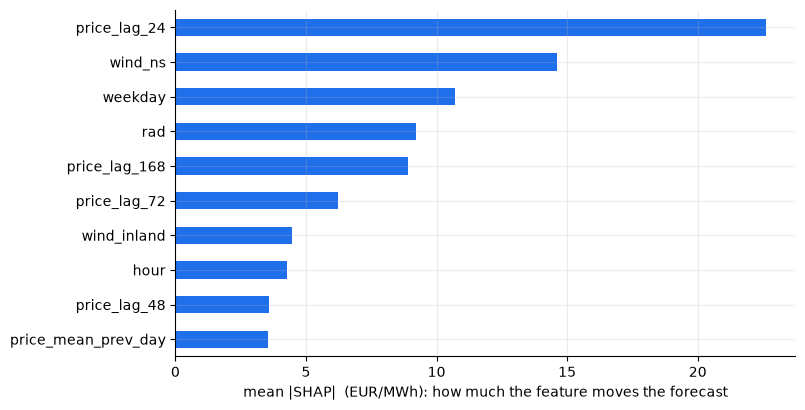

In [20]:
import shap

explainer = shap.TreeExplainer(final_model.models[0.5])               # the median model
sample = test.sample(1500, random_state=0)
shap_values = explainer.shap_values(sample[final_model.features])

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=final_model.features).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
importance.tail(10).plot.barh(ax=ax, color=BLUE)
ax.set_xlabel("mean |SHAP|  (EUR/MWh): how much the feature moves the forecast")
plt.show()

**What you should see.** The most important inputs are **yesterday's price at the same hour**, the **wind forecast at the North Sea**, the **weekday**, last week's price and the
solar radiation. That matches what an energy analyst would say: prices are persistent, wind and sun push them down, weekends are cheaper. When a model's drivers make
domain sense, you can trust it more. If a meaningless feature led the list, that would be a warning sign for leakage or noise.

Now explain **one** hour, to see how a single forecast is built.

In [21]:
row = sample.iloc[[0]]
contrib = pd.Series(explainer.shap_values(row[final_model.features])[0], index=final_model.features)
base = float(np.ravel(explainer.expected_value)[0])
print("hour:", row.index[0].tz_convert(config.TIMEZONE), "   actual price:", round(float(row['price'].iloc[0]), 1))
print(f"average forecast of the model (base value): {base:.1f}")
print(contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6).round(1).to_string())
print(f"sum = forecast: {base + contrib.sum():.1f}   (the model's median forecast: {float(final_model.predict(row)['q50'].iloc[0]):.1f})")

hour: 2026-07-28 00:00:00+02:00    actual price: 161.0
average forecast of the model (base value): 121.6
price_lag_24    -22.80
price_lag_72     11.30
price_lag_168     9.80
weekday           8.70
hour             -7.40
price_lag_48      7.30
sum = forecast: 128.8   (the model's median forecast: 128.8)


**What you should see.** Start from the model's average forecast, add the contributions, and you arrive at the forecast for this hour. The sum matches the model output,
which is the defining property of SHAP.

## 9. Anomalies: which hours are surprising, and why?

A raw price of 150 EUR/MWh is normal at 19:00 in winter and strange at 13:00 on a sunny day. So we do **not** look at the price itself, but at the **forecast error**
(actual minus forecast) compared with what is typical *for that hour of the day*.

We measure "how unusual" with a **robust z-score**: instead of the mean and standard deviation (which outliers distort) we use the **median** and the **MAD**
(median absolute deviation). An hour is flagged when its error is 4 or more robust standard deviations from typical.

In [22]:
residual = bt["price"] - bt["q50"]                       # out-of-sample forecast errors from the backtest
stats = anomaly.residual_stats(residual)                 # median and MAD of the error for each hour of the day
z = anomaly.robust_z(residual, stats)
flags = z.abs() >= 4
events = anomaly.reference_events(bt["price"])           # a market analyst's view: negative prices and the top 1 % of prices
print(f"flagged hours: {int(flags.sum())} of {len(z):,} ({flags.mean():.2%})")
def clean(d):
    # plain numbers for printing
    return {k: (round(float(v), 3) if isinstance(v, (float, np.floating)) else int(v)) for k, v in d.items()}



print("residual detector vs reference events  :", clean(anomaly.precision_recall(flags, events)))

iso = anomaly.flag_by_isolation_forest(features.training_table(frame).loc[bt.index, ["price", "residual_load_fc", "hour", "load_fc"]], contamination=max(float(flags.mean()), 0.005))
print("Isolation Forest, same number of flags  :", clean(anomaly.precision_recall(iso, events)))

flagged hours: 143 of 8,760 (1.63%)
residual detector vs reference events  : {'flagged': 143, 'events': 596, 'precision': 0.517, 'recall': 0.124}


Isolation Forest, same number of flags  : {'flagged': 143, 'events': 596, 'precision': 0.636, 'recall': 0.153}


**What you should see.** Two detectors, scored against the same "remarkable hours" list. The **Isolation Forest** (which sees the raw price) is a little better at catching
extreme prices. The **residual detector** answers a different question: *which hours were surprising given what the model expected from the weather and the calendar*. Both numbers
are shown honestly, instead of only the flattering one. Below, the biggest surprises with a plain-language reason.

In [23]:
typical = anomaly.typical_levels(features.training_table(frame))
top = z.abs().sort_values(ascending=False).head(5).index
shown = bt.loc[top].join(features.training_table(frame)[["residual_load_fc", "wind_onshore_fc", "wind_offshore_fc", "solar_fc", "is_holiday", "weekday"]])
for t, row in shown.iterrows():
    print(t.tz_convert(config.TIMEZONE).strftime("%d.%m.%Y %H:%M"), f" z={z.loc[t]:+.1f}  ", anomaly.explain(row, typical))

01.05.2026 13:00  z=-19.2   price -499 EUR/MWh, 465 lower than forecast (-34); residual load forecast is low (much wind or sun); solar forecast is high; weekend or holiday (low demand)
01.05.2026 14:00  z=-18.7   price -475 EUR/MWh, 443 lower than forecast (-32); residual load forecast is low (much wind or sun); solar forecast is high; weekend or holiday (low demand)
14.09.2026 19:00  z=+16.3   price 697 EUR/MWh, 405 higher than forecast (292); residual load forecast is high (little wind or sun)
26.04.2026 14:00  z=-15.9   price -413 EUR/MWh, 377 lower than forecast (-36); residual load forecast is low (much wind or sun); solar forecast is high; weekend or holiday (low demand)
26.04.2026 13:00  z=-15.6   price -414 EUR/MWh, 379 lower than forecast (-35); residual load forecast is low (much wind or sun); solar forecast is high; weekend or holiday (low demand)


**What you should see.** Each line is one surprising hour, with the price, how far it was from the forecast, and a reason built from the grid situation of that hour
(for example "residual load forecast is low (much wind or sun)" together with a negative price). The reason is generated from the data, not typed by hand.

## 10. From notebook to product: release and monitoring

Everything so far was analysis. A product must also run **without you**. Three more steps:

1. **Train the champion** on all data and save it (`make train`): one file in `models/` plus a small metadata file.
2. **Forecast every morning** before the 12:00 auction (`make forecast`), and save the JSON that the web page and the API read.
3. **Monitor** (`make monitor`): compare every finished forecast with the published prices, and check that the inputs still look like the training data.

On GitHub all three run in a scheduled **GitHub Action** (`.github/workflows/daily.yml`), and GitHub Pages shows the result at no cost.

model trained until : 2026-10-23T21:00:00+00:00
training rows       : 41,998
backtest MAE        : 19.58
interval offset     : 9.7
features            : hour, weekday, month, is_holiday, temp, rad, wind_ns, wind_inland, price_lag_24, price_lag_48, price_lag_72, price_lag_168, price_mean_prev_day, price_min_prev_day, price_max_prev_day, price_mean_prev_7d

latest forecast file is for: 2026-10-26    mean median forecast: 75.79 EUR/MWh


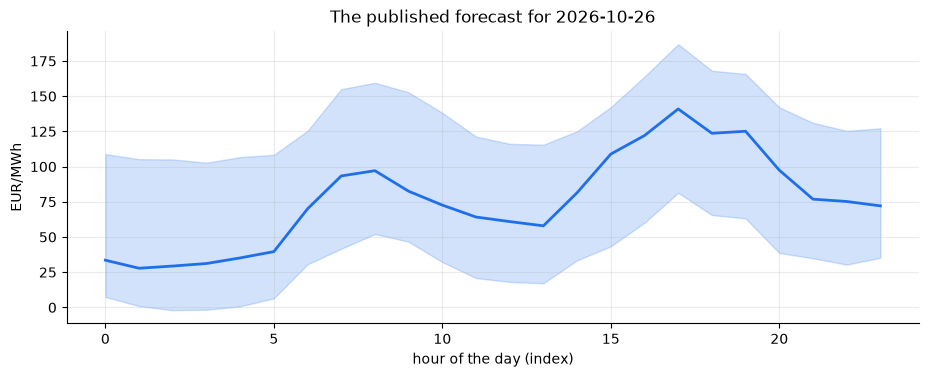

In [24]:
meta = json.loads((config.MODEL_DIR / "metadata.json").read_text())
print("model trained until :", meta["trained_until"])
print("training rows       :", f"{meta['rows']:,}")
print("backtest MAE        :", meta["backtest_mae"])
print("interval offset     :", round(meta["interval_offset"], 1) if "interval_offset" in meta else "n/a")
print("features            :", ", ".join(meta["features"]))

fc = json.loads((config.DOCS_DIR / "forecast.json").read_text())
hours = pd.DataFrame(fc["hours"])
print("\nlatest forecast file is for:", fc["target_day"], "   mean median forecast:", fc["summary"]["mean_q50"], "EUR/MWh")
fig, ax = plt.subplots()
ax.fill_between(range(len(hours)), hours["q10"], hours["q90"], color=BLUE, alpha=0.2)
ax.plot(hours["q50"], color=BLUE, lw=2)
ax.set_xlabel("hour of the day (index)")
ax.set_ylabel("EUR/MWh")
ax.set_title(f"The published forecast for {fc['target_day']}")
plt.show()

**What you should see.** The saved model knows when it was trained and how good it was in the backtest. That number is the reference for monitoring. The chart is the same
forecast the web page shows.

### Monitoring 1: is the error still as small as in the backtest?
Each finished day is scored against the real prices. The *health box* turns to **alert** when the 30-day MAE is 1.5 times the backtest MAE.

In [25]:
history_path = config.DOCS_DIR / "history.json"
records = monitor.load_history(history_path)
print(f"scored days so far: {len(records)}")
if records:
    display(pd.DataFrame([{k: v for k, v in r.items() if k != "hourly"} for r in records]).tail(5))
print(monitor.rolling_health(records, backtest_mae=meta["backtest_mae"]))

scored days so far: 1


,day,hours,mae,mae_naive_168,coverage_80
0,2026-10-25,25,12.29,162.40,1.00


{'status': 'ok', 'days': 1, 'rolling_mae': 12.29, 'rolling_mae_naive_168': 162.4, 'backtest_mae': 19.58, 'coverage_80': 1.0, 'alert_threshold': 29.37}


**What you should see.** Each row is one finished day: the model's MAE, the seasonal naive (m = 168) baseline's MAE and how many real prices fell inside the 80 % interval.
With only a few days of history the health box is based on little evidence, and it says so. It becomes meaningful as days accumulate.

### Monitoring 2: have the inputs drifted? (PSI)
The **population stability index** compares the distribution of an input now with the training data. Below 0.1 is stable, above 0.25 is a large drift. Let us see how it behaves
on data we control: the same distribution, a small shift and a large shift.

In [26]:
rng = np.random.default_rng(0)
reference = pd.Series(rng.normal(50, 10, 5000))
for name, shift in [("same distribution", 0), ("small shift (+3)", 3), ("large shift (+15)", 15)]:
    print(f"{name:20s} PSI = {monitor.psi(reference, pd.Series(rng.normal(50 + shift, 10, 5000))):.3f}")

same distribution    PSI = 0.005
small shift (+3)     PSI = 0.098
large shift (+15)    PSI = 2.013


**What you should see.** About 0 for the same distribution, a small number (around 0.1) for the small shift, and a value far above 0.25 for the large one. In the project the daily job
computes this for load, residual load, North Sea wind and temperature, **against training rows of the same calendar months** (comparing autumn with a whole year would
always look like drift).

---

## Recap: the ideas worth remembering

1. **Write the task down first**, including what is known at forecast time. It decides everything else.
2. **Test for leakage with code**, not with good intentions. And watch for traps such as the 25-hour day.
3. **Beat the best simple baseline, not the weakest** (seasonal naive, Holt-Winters, SARIMA), and measure with errors that are safe for your data (not MAPE for prices near zero).
4. **Give an interval, not only a number,** and check that the interval is honest. If it is not, calibrate it.
5. **Backtest with rolling origin.** Every test month is predicted by a model that only knew the past.
6. **Explain the model** (SHAP) and the surprises (anomalies). Report the flattering and the unflattering results.
7. **A model is not finished when it is trained.** Release it, run it every day, and monitor error and drift.

## Where to go next
- `README.md` and `MODEL_CARD.md`: the short version, the limits and the data licenses.
- `tests/`: how each idea above is protected by an automated test.
- Try it: change `CALIBRATION_DAYS`, or remove `price_lag_24` from `SAFE_FEATURES` in `src/epf/features.py`, rerun sections 5 to 7 and watch what happens to the error.

*This is a learning and demonstration project, not trading advice.*